<a href="https://colab.research.google.com/github/JulTob/Modelling/blob/main/GLM/GLM_2_4_n_fraude_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 2.4 · Demasiados ceros: alertas antifraude

🏵 **Pregunta.** Si una póliza no ha generado alertas, ¿está fuera del alcance del sistema o ha sido vigilada sin que aparezca ninguna?

- **Unidad:** una póliza de esta cartera.
- **Respuesta:** `n_fraude`, el número de **alertas** durante su exposición. Una alerta no equivale a fraude demostrado.
- **Exposición:** `exposicion`, conservada en la escala del CSV. Las tasas se expresan por una unidad de esa exposición; no las llamaremos anuales sin definir la conversión.
- **Propósito:** describir y modelar las alertas, sin atribuir efectos causales ni identificar con certeza la pertenencia de cada póliza.

### Qué deberíamos poder explicar al terminar

1. Por qué muchos ceros no bastan para afirmar inflación de ceros.
2. Cómo se diferencian la variación adicional de una NB y la mezcla de un ZIP.
3. Qué significan los dos predictores del ZIP y sus cuatro cantidades: $π$, $μ$, probabilidad de cero y media total.
4. Qué sostienen la simulación, el AIC y el gráfico, y qué queda por comprobar.

**Recorrido:** preparar → describir → comparar con NB → formular ZIP → interpretar predicciones → justificar una conclusión. Antes de cada bloque de código, identifica su pregunta; después, busca la comprobación indicada. Fuente: [Caso 2, apartado 4 de los apuntes](https://asunmayoral.github.io/GLM/caso2/caso2_conteos.html#sec-u24).

## 0 · Preparar y observar

### 0.1 · Cargar los datos y conservar sus unidades

⚙️ La primera celda carga `tidyverse`, lee una revisión fijada del CSV y comprueba que la exposición exista y sea positiva. `glimpse` permite reconocer columnas y tipos; `summary` resume las exposiciones. **Comprueba:** cada fila debe representar la unidad que queremos modelar y el tiempo observado debe tener una interpretación consistente. Estas salidas no prueban todavía ningún modelo.


In [2]:
library(tidyverse)

# Fuente de datos del equipo 07
repositorio <- "https://raw.githubusercontent.com/JulTob/Modelling/698dad06c4228ea79319fdba27647a0c61474703/GLM/"

cartera <- read_csv(
    paste0(repositorio, "cartera.csv"),
    show_col_types = FALSE
    )

# Comprobar que los datos son válidos
stopifnot(
    nrow(cartera) > 0,
    all(c("n_fraude", "exposicion")    %in% names(cartera)),
    all(!is.na(cartera$exposicion)),
    all(cartera$exposicion > 0)
    )

glimpse(cartera)
summary(cartera$exposicion)

Rows: 3,062
Columns: 40
$ id_poliza           <dbl> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15,…
$ id_agencia          <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,…
$ id_region           <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,…
$ antiguedad          <dbl> 1.082, 6.687, 5.732, 1.397, 1.968, 3.159, 3.821, 7…
$ exposicion          <dbl> 0.1082, 0.6687, 0.5732, 0.1397, 0.1968, 0.3159, 0.…
$ edad_conductor      <dbl> 33, 44, 62, 25, 66, 25, 18, 44, 49, 36, 77, 36, 39…
$ edad_tramo          <chr> "25-35", "35-65", "35-65", "18-25", "65+", "18-25"…
$ antiguedad_carnet   <dbl> 7, 13, 36, 6, 36, 7, 0, 11, 30, 7, 49, 12, 16, 17,…
$ potencia_cv         <dbl> 85, 142, 118, 76, 55, 120, 143, 64, 113, 136, 141,…
$ cilindrada          <dbl> 1417, 2423, 1831, 1278, 824, 1816, 1730, 1006, 162…
$ antiguedad_vehiculo <dbl> 6, 12, 6, 9, 10, 6, 11, 10, 19, 4, 7, 12, 19, 4, 7…
$ valor_vehiculo      <dbl> 35790, 22089, 31528, 25948, 20714, 15821, 23040, 2…
$ densidad      

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
 0.0100  0.2194  0.3768  0.4207  0.5934  0.9996 

### 0.2 · Preparar la misma cartera para los tres modelos

⚙️ La siguiente celda prepara `datos_ceros` con las variables necesarias, comprueba ausencias y exige recuentos enteros no negativos y exposiciones positivas. Conserva las referencias **urbana, particular y turismo** para interpretar después los coeficientes.

No se descartan pólizas por valores ausentes de otras respuestas, como `coste_medio`. Así, la comparación corresponde a las mismas observaciones. **Lee la salida:** número de pólizas, número y proporción de ceros, y media de alertas. Deben aparecer **3062 pólizas y 2551 ceros**. La media es un recuento por póliza; aún no es una tasa por exposición.


In [3]:
# Reutilizamos cartera, cargada arriba desde la revisión fijada del CSV.
# MASS::glm.nb y glmmTMB::glmmTMB se invocan por su nombre completo.
paquetes_ceros <- c("MASS", "glmmTMB")
faltan_paquetes <- paquetes_ceros[
  !vapply(paquetes_ceros, requireNamespace, logical(1), quietly = TRUE)
]
if (length(faltan_paquetes) > 0L) {
  install.packages(faltan_paquetes, repos = "https://cloud.r-project.org")
}

variables_ceros <- c(
  "n_fraude", "exposicion", "potencia_cv",
  "zona_circulacion", "uso", "tipo_vehiculo"
)
faltan_columnas <- setdiff(c("id_poliza", variables_ceros), names(cartera))
if (length(faltan_columnas) > 0L) {
  stop("Faltan columnas: ", paste(faltan_columnas, collapse = ", "))
}

datos_ceros <- cartera |>
  dplyr::select(id_poliza, dplyr::all_of(variables_ceros))

# Revisamos solo las variables que entran en los modelos.
# No eliminamos filas por NA de otras respuestas, como coste_medio.
if (anyNA(datos_ceros[variables_ceros])) {
  stop("Hay valores ausentes en variables del modelo: revisarlos antes de ajustar.")
}
stopifnot(
  nrow(datos_ceros) > 0L,
  all(is.finite(datos_ceros$n_fraude)),
  all(datos_ceros$n_fraude >= 0),
  all(datos_ceros$n_fraude == floor(datos_ceros$n_fraude)),
  all(is.finite(datos_ceros$exposicion)),
  all(datos_ceros$exposicion > 0),
  all(is.finite(datos_ceros$potencia_cv))
)

# Referencias explícitas, como en el ejemplo de los apuntes.
# fct_relevel conserva cualquier otro nivel que exista en los datos.
datos_ceros <- datos_ceros |>
  dplyr::mutate(
    zona_circulacion = forcats::fct_relevel(factor(zona_circulacion), "urbana"),
    uso = forcats::fct_relevel(factor(uso), "particular"),
    tipo_vehiculo = forcats::fct_relevel(factor(tipo_vehiculo), "turismo")
  )

c(
  polizas = nrow(datos_ceros),
  ceros_observados = sum(datos_ceros$n_fraude == 0),
  proporcion_ceros = mean(datos_ceros$n_fraude == 0),
  media_alertas = mean(datos_ceros$n_fraude)
)


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘colorspace’, ‘fracdiff’, ‘lmtest’, ‘timeDate’, ‘urca’, ‘RcppArmadillo’, ‘rbibutils’, ‘cowplot’, ‘Deriv’, ‘forecast’, ‘Rdpack’, ‘minqa’, ‘nloptr’, ‘doBy’, ‘zoo’, ‘RTMB’, ‘TMB’, ‘lme4’, ‘numDeriv’, ‘reformulas’, ‘pbkrtest’, ‘sandwich’, ‘RcppEigen’




polizas ceros_observados proporcion_ceros    media_alertas 
    3062.0000000     2551.0000000        0.8331156        0.2351404

### 0.3 · Leer la distribución observada

🔰 El siguiente gráfico es un **diagrama de barras de frecuencias para un conteo discreto**: cada barra representa un número entero de alertas; su altura cuenta pólizas. **Tomato** indica cero alertas y **gold**, algún número positivo.

Antes de continuar, localiza la barra de cero y observa cómo se reparten las frecuencias entre los recuentos mayores. Una barra alta en cero describe la cartera, pero no permite distinguir ceros estructurales de ceros de una póliza vigilada. Además, reúne pólizas con diferentes características y exposiciones. La pregunta siguiente será: **¿cuántos ceros predice un modelo que tiene en cuenta esas diferencias?**


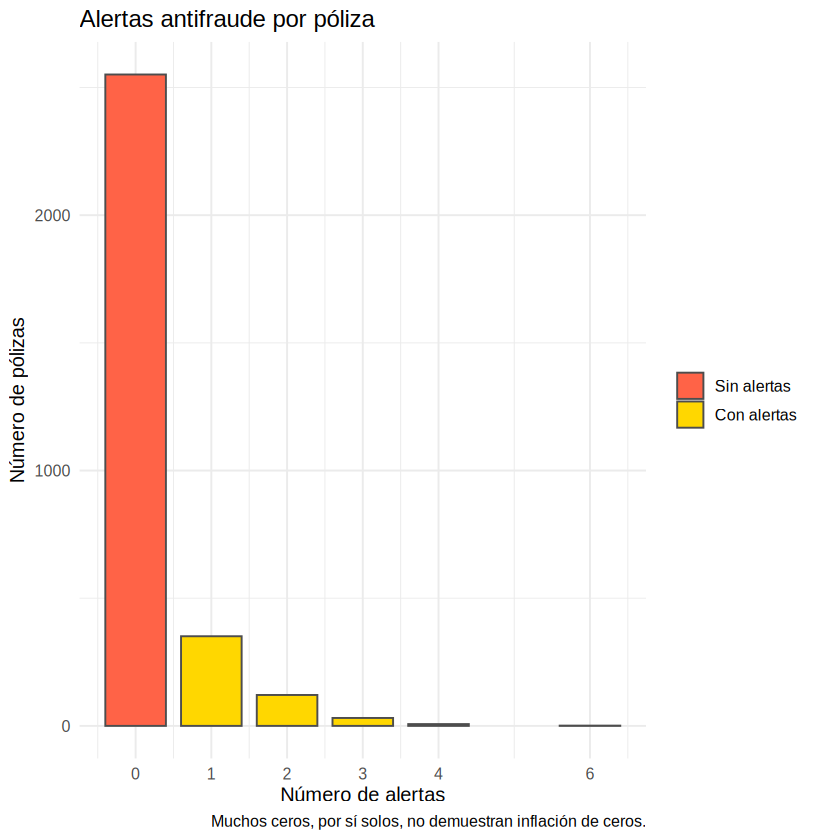

In [4]:
frecuencias_alertas <- datos_ceros |>
  dplyr::count(n_fraude, name = "polizas") |>
  dplyr::mutate(
    resultado = ifelse(n_fraude == 0, "Sin alertas", "Con alertas")
  )

grafico_alertas <- ggplot(frecuencias_alertas, aes(n_fraude, polizas)) +
  geom_col(aes(fill = resultado), width = 0.8, colour = "grey30") +
  scale_fill_manual(
    values = c("Sin alertas" = "tomato", "Con alertas" = "gold"),
    breaks = c("Sin alertas", "Con alertas")
  ) +
  scale_x_continuous(breaks = sort(unique(datos_ceros$n_fraude))) +
  labs(
    title = "Alertas antifraude por póliza",
    x = "Número de alertas", y = "Número de pólizas", fill = NULL,
    caption = "Muchos ceros, por sí solos, no demuestran inflación de ceros."
  ) +
  theme_minimal(base_size = 12)

grafico_alertas


## 1 · ¿Sobran ceros respecto a qué modelo?

🔰 Cada póliza tiene su propia media esperada, porque cambian sus características y su exposición. Comparamos los ceros observados con **la suma de las probabilidades individuales de cero**, no con una única probabilidad calculada a partir de la media de toda la cartera.

Ajustamos dos modelos de un solo proceso, con la misma respuesta, filas y predictores:

`n_fraude ~ potencia_cv + zona_circulacion + uso + tipo_vehiculo + offset(log(exposicion))`

- **Poisson:** media $μ_{[i]}$, varianza $μ_{[i]}$ y $P(Y_{[i]}=0)=\exp(-μ_{[i]})$.
- **Binomial negativa (NB2):** media $μ_{[i]}$, varianza $μ_{[i]}+μ_{[i]}^2/θ$ y $P(Y_{[i]}=0)=(θ/(θ+μ_{[i]}))^{θ}$.

La NB permite variación adicional y puede generar muchos ceros sin añadir una clase estructural. Un exceso respecto a Poisson puede desaparecer al compararlo con NB. En cada modelo, $μ_{[i]}$ procede de su propio ajuste.

### Qué calcula la siguiente celda

1. Ajusta Poisson y NB y comprueba su convergencia.
2. Suma sus probabilidades de cero. El cociente **observados/esperados** vale aproximadamente 1 si reproducen el número global; mayor que 1 indica más ceros observados y menor que 1, menos.
3. Simula **1000 carteras desde la NB ajustada**, manteniendo covariables, exposiciones y parámetros estimados. Cuenta los ceros de cada réplica para obtener una referencia de variación.

**Cómo leer la simulación.** Sitúa los 2551 ceros observados respecto al intervalo central del 95 % de los recuentos simulados. Es un intervalo de referencia para ese resumen, no un intervalo de confianza de un parámetro. El diagnóstico es **bilateral**: aproxima ambas colas por Monte Carlo y toma el doble de la menor, limitado a 1. La corrección «+1» evita informar un valor cero.

⚜️ Este diagnóstico no incorpora incertidumbre de los parámetros ni reajusta el modelo en cada réplica. Un resultado compatible con NB significa que **este resumen** no revela una discrepancia clara; no prueba que toda su distribución sea adecuada. Tampoco una discrepancia demostraría, por sí sola, una clase estructural. [Contexto docente](https://asunmayoral.github.io/GLM/caso2/caso2_conteos.html#sec-u24).


In [5]:
formula_conteo <- n_fraude ~
  potencia_cv + zona_circulacion + uso + tipo_vehiculo +
  offset(log(exposicion))

modelo_poisson <- glm(
  formula_conteo, family = poisson(link = "log"), data = datos_ceros
)
modelo_nb <- MASS::glm.nb(formula_conteo, data = datos_ceros)

if (!isTRUE(modelo_poisson$converged) || !isTRUE(modelo_nb$converged)) {
  stop("Un modelo de referencia no ha convergido: revisar antes de comparar.")
}
if (!is.null(modelo_nb$th.warn)) {
  stop("La estimación de dispersión NB requiere revisión: ", modelo_nb$th.warn)
}

μ_poisson <- fitted(modelo_poisson)
μ_nb <- fitted(modelo_nb)
ceros_observados <- sum(datos_ceros$n_fraude == 0)
ceros_esperados <- c(
  Poisson = sum(dpois(0, lambda = μ_poisson)),
  NB = sum(dnbinom(0, mu = μ_nb, size = modelo_nb$theta))
)

comparacion_ceros <- tibble::tibble(
  modelo = names(ceros_esperados),
  observados = ceros_observados,
  esperados = unname(ceros_esperados),
  ratio_observados_esperados = observados / esperados
)
print(comparacion_ceros)

set.seed(2026)
B <- 1000L
ceros_simulados_nb <- replicate(
  B,
  sum(rnbinom(nrow(datos_ceros), mu = μ_nb, size = modelo_nb$theta) == 0)
)
cola_superior_mc <- (1 + sum(ceros_simulados_nb >= ceros_observados)) / (B + 1)
cola_inferior_mc <- (1 + sum(ceros_simulados_nb <= ceros_observados)) / (B + 1)
p_bilateral_mc <- min(1, 2 * min(cola_superior_mc, cola_inferior_mc))
intervalo_simulado <- quantile(ceros_simulados_nb, c(0.025, 0.975))

c(
  ceros_observados = ceros_observados,
  media_simulada_NB = mean(ceros_simulados_nb),
  percentil_2_5 = unname(intervalo_simulado[1]),
  percentil_97_5 = unname(intervalo_simulado[2]),
  p_bilateral_MC = p_bilateral_mc,
  cola_superior_MC = cola_superior_mc
)


# A tibble: 2 × 4
  modelo  observados esperados ratio_observados_esperados
  <chr>        <int>     <dbl>                      <dbl>
1 Poisson       2551     2459.                       1.04
2 NB            2551     2541.                       1.00


ceros_observados media_simulada_NB     percentil_2_5    percentil_97_5 
     2551.0000000      2541.4200000      2503.0000000      2580.0000000 
   p_bilateral_MC  cola_superior_MC 
        0.6313686         0.3156843

## 2 · Formular el ZIP: dos orígenes posibles para un cero

🏵 Introducimos una pertenencia **no observada**, $U_{[i]}$:

1. Con probabilidad $π_{[i]}$, la póliza está **fuera del perímetro**: $U_{[i]}=1$ y $Y_{[i]}=0$ necesariamente.
2. Con probabilidad $1-π_{[i]}$, está **vigilada**: $U_{[i]}=0$ y su número de alertas sigue una Poisson de media $μ_{[i]}$. Esa Poisson también puede dar cero.

Esta lectura del perímetro es la **hipótesis del modelo**, no una etiqueta observada en el CSV. $U_{[i]}$ sigue una Bernoulli de probabilidad $π_{[i]}$; el conteo de las vigiladas conserva 0, 1, 2, …

### 2.1 · Cómo se construye la mezcla

$$
ZIP(π,μ)=πδ_0+(1-π)Poisson(μ),
$$

donde $δ_0$ concentra toda su probabilidad en cero. Multiplicamos **toda la Poisson**, incluido su cero, por $1-π$ y añadimos $π$ en cero. No se elimina ni se trunca una cola: todo recuento positivo sigue siendo posible.

Frente a una Poisson con **la misma media de componente $μ$**, el aumento neto en cero es

$$
[π+(1-π)e^{-μ}]-e^{-μ}=π(1-e^{-μ}).
$$

La cantidad añadida por la clase estructural es $π$, pero el aumento neto es menor porque también se reduce el cero original de la Poisson. Al comparar modelos ajustados por separado, sus medias pueden diferir: esta identidad a $μ$ fijo no atribuye la diferencia entre sus ajustes. [Construcción ZIP y hurdle](https://zeileis.codeberg.page/countreg/vignettes/zero-augmented.html).

### 2.2 · Dos predictores, dos preguntas

**Parte de conteo — ¿a qué ritmo aparecen alertas entre las vigiladas?**

$$
\begin{aligned}
\log μ_{[i]} = {}& \log t_{[i]} + β_0 + β_{p}\,\text{potencia}_{[i]} \\
&+ β_{m}\,\text{mixta}_{[i]} + β_{r}\,\text{rural}_{[i]} \\
&+ β_{u}\,\text{comercial}_{[i]} + β_{v}\,\text{moto}_{[i]}
+ β_{f}\,\text{furgoneta}_{[i]} .
\end{aligned}
$$

$t_{[i]}$ es `exposicion`; las categorías son indicadores 0/1, con referencias **urbana, particular y turismo**. La potencia se mantiene en CV. El enlace log transforma la media: al exponenciar obtenemos una media positiva. No estamos transformando los recuentos observados.

El coeficiente de $\log t_{[i]}$ queda fijado en 1: eso es el **offset**. Si llamamos $η_{[i]}$ a la parte con los coeficientes $β$, entonces $μ_{[i]}=t_{[i]}e^{η_{[i]}}$ y la tasa es $λ_{[i]}=μ_{[i]}/t_{[i]}=e^{η_{[i]}}$. A iguales características, duplicar la exposición duplica la media del componente de conteo.

**Parte estructural — ¿qué probabilidad hay de quedar fuera del perímetro?**

$$
\log\left(\frac{π_{[i]}}{1-π_{[i]}}\right)
= γ_0 + γ_{u}\,\text{comercial}_{[i]}
+ γ_{p}\,\text{potencia}_{[i]} .
$$

El enlace **logit** actúa sobre $π$ y su inversa produce una probabilidad entre 0 y 1. Usamos `uso + potencia_cv`, como en la especificación docente. La exposición entra en el conteo; aquí suponemos que la pertenencia al perímetro no cambia con el tiempo observado.

### 2.3 · Qué se estima y qué mirar en la salida

⚜️ $μ_{[i]}$ es la media de **todas las vigiladas**, incluidas las que terminan con cero. No es la media solo de los recuentos positivos. Los dos submodelos se estiman **conjuntamente**: cada cero puede proceder de ambas partes. Una logística de `n_fraude == 0` modelaría el cero observado y no esta pertenencia latente.

⚙️ La próxima celda ajusta el ZIP, comprueba convergencia y Hessiana, muestra `summary` y compara AIC. En el resumen, localiza **Conditional model** para los $β$ y **Zero-inflation model** para los $γ$. Sus coeficientes están en escalas distintas. Superar los controles numéricos permite seguir; no demuestra adecuación estadística.

En **Conditional model**, la columna `Estimate` de `potencia_cv` estima $β_p$. Para interpretar 50 CV adicionales, calculamos $e^{50β_p}$: es la razón entre las tasas del componente vigilado, manteniendo las demás características. En **Zero-inflation model**, `Estimate` corresponde a $γ$; su exponencial compara las *odds* de pertenencia estructural.

El modelo supone pólizas independientes tras condicionar por los predictores y el mecanismo descrito. [Especificación de glmmTMB](https://glmmtmb.github.io/glmmTMB/reference/glmmTMB.html).


In [6]:
modelo_zip <- glmmTMB::glmmTMB(
  formula_conteo,
  ziformula = ~ uso + potencia_cv,
  family = poisson(link = "log"),
  data = datos_ceros
)

# Comprobación numérica antes de interpretar estimaciones o comparar AIC.
if (modelo_zip$fit$convergence != 0L || !isTRUE(modelo_zip$sdr$pdHess)) {
  stop("El ZIP requiere revisión numérica: convergencia o Hessiana no adecuadas.")
}

summary(modelo_zip)

# Mismas observaciones, misma respuesta y verosimilitudes comparables.
# Un AIC menor favorece el ajuste relativo dentro de estos candidatos.
AIC(modelo_poisson, modelo_nb, modelo_zip)


 Family: poisson  ( log )
Formula:          
n_fraude ~ potencia_cv + zona_circulacion + uso + tipo_vehiculo +  
    offset(log(exposicion))
Zero inflation:            ~uso + potencia_cv
Data: datos_ceros

      AIC       BIC    logLik -2*log(L)  df.resid 
   3352.1    3412.4   -1666.0    3332.1      3052 


Conditional model:
                        Estimate Std. Error z value Pr(>|z|)    
(Intercept)            -0.846092   0.279746  -3.024 0.002490 ** 
potencia_cv             0.007096   0.001863   3.810 0.000139 ***
zona_circulacionmixta   0.181984   0.129803   1.402 0.160915    
zona_circulacionrural   0.176297   0.143289   1.230 0.218563    
usocomercial            0.144578   0.152112   0.950 0.341873    
tipo_vehiculofurgoneta  0.107415   0.121948   0.881 0.378412    
tipo_vehiculomoto       0.093368   0.122064   0.765 0.444323    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Zero-inflation model:
              Estimate Std. Error z value Pr(>|z|)   
(Interc

,df,AIC
,<dbl>,<dbl>
modelo_poisson,7,3464.794
modelo_nb,8,3370.312
modelo_zip,10,3352.094


## 3 · Traducir el modelo a predicciones

### 3.1 · Cuatro cantidades que responden a preguntas distintas

- **$π_{[i]}$ — pertenencia estructural:** probabilidad de estar fuera del perímetro antes de observar el recuento.
- **$μ_{[i]}$ — media si está vigilada:** número esperado de alertas del componente Poisson, incluidos sus ceros.
- **$P_{0[i]}=π_{[i]}+(1-π_{[i]})\exp(-μ_{[i]})$ — cero observado:** suma de los dos caminos que pueden producirlo.
- **$m_{[i]}=(1-π_{[i]})μ_{[i]}$ — media total:** número esperado de alertas antes de conocer la pertenencia. La otra clase aporta cero a la media.

La varianza del ZIP es $(1-π_{[i]})μ_{[i]}(1+π_{[i]}μ_{[i]})$: la mezcla permite más variación que una Poisson de la misma media total.

**Después de observar cero**, podemos actualizar la pertenencia:

$$
P(U_{[i]}=1\mid Y_{[i]}=0)=\frac{π_{[i]}}{P_{0[i]}}.
$$

Si aparece alguna alerta, esa probabilidad es **0 dentro de este modelo**. Un cero mantiene la ambigüedad: no produce una clasificación cierta.

### 3.2 · Ejemplo guiado: $μ=2$, $π=0.4$

💡 **Ilustración matemática, no resultado de nuestra cartera.**

1. La Poisson de partida da cero con probabilidad $e^{-2}\approx0.135335$.
2. La parte vigilada pesa $0.6$: su aportación al cero es $0.6e^{-2}\approx0.081201$. Cada probabilidad de un recuento positivo también se multiplica por 0.6.
3. Añadimos la masa estructural: $P_0=0.4+0.081201\approx\mathbf{0.481201}$.
4. El aumento neto frente a esa Poisson es $0.481201-0.135335\approx\mathbf{0.345866}=0.4(1-e^{-2})$. La media total es $m=0.6\times2=\mathbf{1.2}$ alertas.
5. Tras observar cero, la probabilidad estructural pasa de 0.4 a $0.4/0.481201\approx0.831$. Sigue siendo menor que 1.

### 3.3 · Qué calcula la siguiente celda

En `glmmTMB`, **`zprob` devuelve $π$**, **`conditional` devuelve $μ$** y **`response` devuelve $m$**. La celda calcula $P_0$ y la pertenencia actualizada, comprueba límites e identidades y muestra ocho pólizas. Lee cada columna con las cuatro definiciones anteriores; `prob_fuera_dado_recuento` incorpora además el recuento observado. [Documentación de las predicciones](https://glmmtmb.github.io/glmmTMB/reference/predict.glmmTMB.html).

`media_si_vigilada` y `media_total` son números esperados de alertas durante la exposición de cada póliza. `tasa_si_vigilada` se expresa en alertas por unidad de exposición. Las columnas de probabilidad no tienen unidades.

Después suma $P_{0[i]}$ para obtener ceros esperados y superpone frecuencias ZIP al gráfico. **Barras:** datos; **puntos y línea:** frecuencias esperadas. El gráfico muestra hasta el máximo observado; ese límite de visualización no trunca ni renormaliza la distribución del modelo.


# A tibble: 8 × 9
  id_poliza n_fraude exposicion prob_fuera prob_cero media_si_vigilada
      <dbl>    <dbl>      <dbl>      <dbl>     <dbl>             <dbl>
1         1        0      0.108      0.632     0.964             0.102
2         2        3      0.669      0.519     0.738             0.786
3         3        0      0.573      0.567     0.770             0.759
4         4        0      0.140      0.649     0.959             0.123
5         5        0      0.197      0.686     0.963             0.125
6         6        0      0.316      0.563     0.862             0.381
7         7        2      0.382      0.517     0.824             0.452
8         8        1      0.781      0.671     0.835             0.695
# ℹ 3 more variables: tasa_si_vigilada <dbl>, media_total <dbl>,
#   prob_fuera_dado_recuento <dbl>
          ceros_observados        ceros_esperados_ZIP 
              2551.0000000               2549.7282314 
fraccion_estructural_media 
                 0.5532023 
# A ti

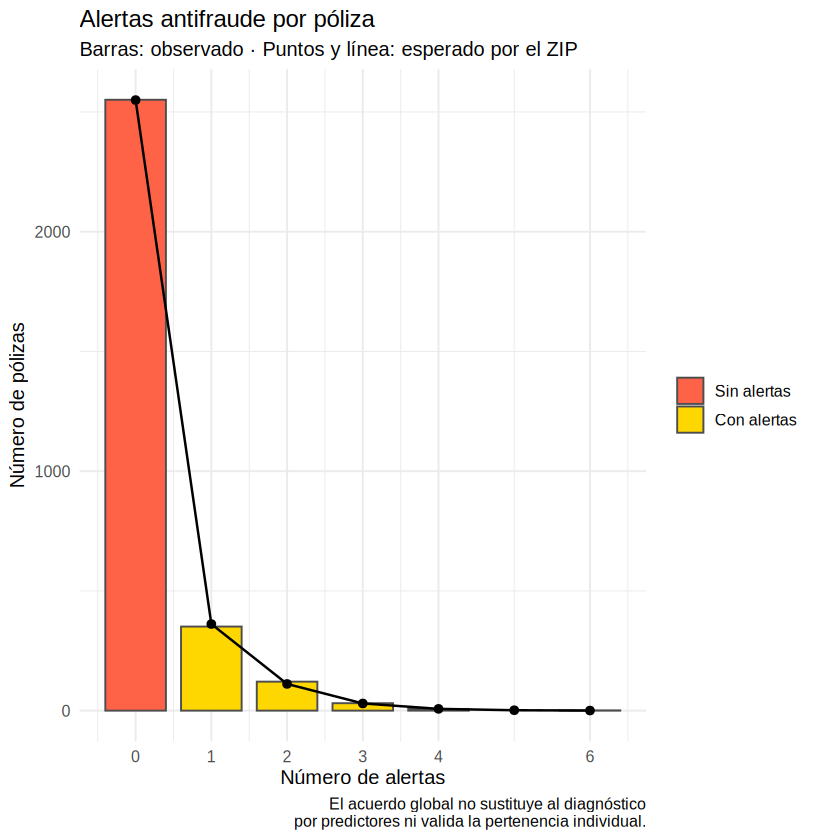

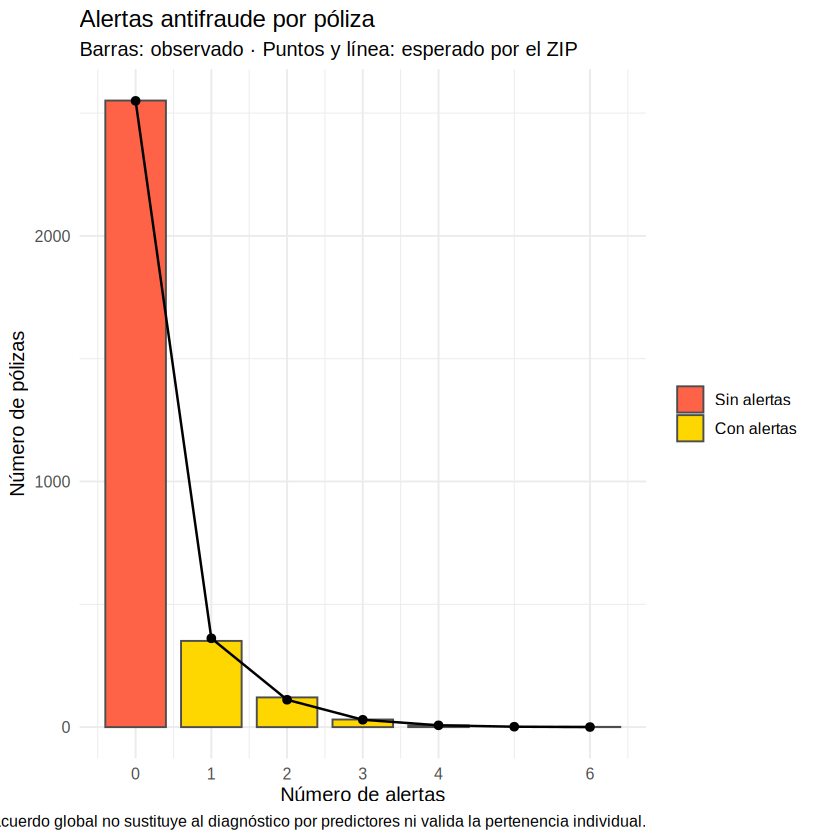

In [8]:
π <- as.numeric(predict(modelo_zip, type = "zprob"))
μ <- as.numeric(predict(modelo_zip, type = "conditional"))
p_cero <- π + (1 - π) * exp(-μ)
media_total <- (1 - π) * μ

# Probabilidad estructural actualizada con el recuento observado.
es_cero <- datos_ceros$n_fraude == 0
prob_fuera_dado_recuento <- numeric(nrow(datos_ceros))
prob_fuera_dado_recuento[es_cero] <- π[es_cero] / p_cero[es_cero]

# Verifica el significado de las salidas de la API y los límites probabilísticos.
stopifnot(
  all(is.finite(μ)), all(μ > 0),
  all(is.finite(π)), all(π >= 0 & π <= 1),
  all(p_cero >= π - 1e-12 & p_cero <= 1 + 1e-12),
  all(is.finite(prob_fuera_dado_recuento)),
  all(prob_fuera_dado_recuento >= 0 & prob_fuera_dado_recuento <= 1 + 1e-12),
  isTRUE(all.equal(
    media_total,
    as.numeric(predict(modelo_zip, type = "response")),
    tolerance = 1e-8
  ))
)

predicciones_zip <- datos_ceros |>
  dplyr::transmute(
    id_poliza, n_fraude, exposicion,
    prob_fuera = π,
    prob_cero = p_cero,
    media_si_vigilada = μ,
    tasa_si_vigilada = μ / exposicion,
    media_total = media_total,
    prob_fuera_dado_recuento = prob_fuera_dado_recuento
  )
print(dplyr::slice_head(predicciones_zip, n = 8))

print(c(
  ceros_observados = sum(es_cero),
  ceros_esperados_ZIP = sum(p_cero),
  fraccion_estructural_media = mean(π)
))

# Superponemos las frecuencias esperadas del ZIP al gráfico observado.
# Se muestran los valores hasta el máximo observado; no se renormaliza la cola.
recuentos <- seq.int(0L, max(datos_ceros$n_fraude))
frecuencias_zip <- tibble::tibble(
  n_fraude = recuentos,
  esperadas = vapply(
    recuentos,
    function(k) {
      if (k == 0L) sum(p_cero) else sum((1 - π) * dpois(k, lambda = μ))
    },
    numeric(1)
  )
)

grafico_alertas +
  geom_line(
    data = frecuencias_zip, aes(n_fraude, esperadas),
    inherit.aes = FALSE, colour = "black", linewidth = 0.7
  ) +
  geom_point(
    data = frecuencias_zip, aes(n_fraude, esperadas),
    inherit.aes = FALSE, colour = "black", size = 2
  ) +
  labs(
    subtitle = "Barras: observado · Puntos y línea: esperado por el ZIP",
    caption = "El acuerdo global no sustituye al diagnóstico\npor predictores ni valida la pertenencia individual."
  )
π <- as.numeric(predict(modelo_zip, type = "zprob"))
μ <- as.numeric(predict(modelo_zip, type = "conditional"))
p_cero <- π + (1 - π) * exp(-μ)
media_total <- (1 - π) * μ

# Probabilidad estructural actualizada con el recuento observado.
es_cero <- datos_ceros$n_fraude == 0
prob_fuera_dado_recuento <- numeric(nrow(datos_ceros))
prob_fuera_dado_recuento[es_cero] <- π[es_cero] / p_cero[es_cero]

# Verifica el significado de las salidas de la API y los límites probabilísticos.
stopifnot(
  all(is.finite(μ)), all(μ > 0),
  all(is.finite(π)), all(π >= 0 & π <= 1),
  all(p_cero >= π - 1e-12 & p_cero <= 1 + 1e-12),
  all(is.finite(prob_fuera_dado_recuento)),
  all(prob_fuera_dado_recuento >= 0 & prob_fuera_dado_recuento <= 1 + 1e-12),
  isTRUE(all.equal(
    media_total,
    as.numeric(predict(modelo_zip, type = "response")),
    tolerance = 1e-8
  ))
)

predicciones_zip <- datos_ceros |>
  dplyr::transmute(
    id_poliza, n_fraude, exposicion,
    prob_fuera = π,
    prob_cero = p_cero,
    media_si_vigilada = μ,
    tasa_si_vigilada = μ / exposicion,
    media_total = media_total,
    prob_fuera_dado_recuento = prob_fuera_dado_recuento
  )
print(dplyr::slice_head(predicciones_zip, n = 8))

print(c(
  ceros_observados = sum(es_cero),
  ceros_esperados_ZIP = sum(p_cero),
  fraccion_estructural_media = mean(π)
))

# Superponemos las frecuencias esperadas del ZIP al gráfico observado.
# Se muestran los valores hasta el máximo observado; no se renormaliza la cola.
recuentos <- seq.int(0L, max(datos_ceros$n_fraude))
frecuencias_zip <- tibble::tibble(
  n_fraude = recuentos,
  esperadas = vapply(
    recuentos,
    function(k) {
      if (k == 0L) sum(p_cero) else sum((1 - π) * dpois(k, lambda = μ))
    },
    numeric(1)
  )
)

grafico_alertas +
  geom_line(
    data = frecuencias_zip, aes(n_fraude, esperadas),
    inherit.aes = FALSE, colour = "black", linewidth = 0.7
  ) +
  geom_point(
    data = frecuencias_zip, aes(n_fraude, esperadas),
    inherit.aes = FALSE, colour = "black", size = 2
  ) +
  labs(
    subtitle = "Barras: observado · Puntos y línea: esperado por el ZIP",
    caption = "El acuerdo global no sustituye al diagnóstico por predictores ni valida la pertenencia individual."
  )


## 4 · Cómo interpretar y comprobar el resultado

### 4.1 · Leer coeficientes en su escala

- **Conteo del ZIP:** $\exp(β)$ es una razón de tasas entre pólizas vigiladas para el contraste correspondiente, manteniendo los demás predictores. Para 50 CV adicionales, usa $\exp(50β_p)$.
- **Parte estructural:** $\exp(γ)$ es una razón de *odds* de quedar **fuera** del perímetro. Un coeficiente positivo aumenta esa probabilidad; uno negativo la reduce. No es una razón de probabilidades.
- **Media total:** si un predictor afecta a ambas partes, su efecto pasa por $(1-π)μ$. No se obtiene leyendo solo uno de sus coeficientes.
- **Interceptos:** al exponenciarlos obtenemos una tasa o unas odds de referencia, no una razón entre grupos. La potencia sin centrar sitúa el intercepto en 0 CV, fuera de un perfil habitual.

### 4.2 · Separar las comprobaciones

- **Número de ceros:** un ratio cercano a 1 y un resultado compatible en la simulación revisan este resumen concreto.
- **AIC:** $AIC=-2ℓ+2K$, con $ℓ$ la log-verosimilitud maximizada y $K$ el número de parámetros estimados. Menor AIC favorece el ajuste relativo, penalizando complejidad, entre candidatos con las mismas filas y respuesta. No es un porcentaje de acierto ni una prueba del mecanismo.
- **Gráfico:** el acuerdo de frecuencias comprueba la distribución global. Falta estudiar residuos y patrones por predictores; una buena coincidencia global puede ocultarlos.
- **Alcance:** no hemos comparado ZINB ni hurdle. El CSV no conserva `attr(cartera, "verdad")`: tampoco hemos validado coeficientes contra el generador ni identificado con certeza qué pólizas están fuera.

⚜️ **ZIP y hurdle tienen mecanismos distintos.** En ZIP, una póliza vigilada también puede producir cero. En hurdle, todos los ceros proceden de la barrera y la distribución de los positivos se trunca en cero. La mezcla estudiada aquí conserva la Poisson completa.

### Fuentes para repasar

- [Apuntes: Caso 2, apartado 4](https://asunmayoral.github.io/GLM/caso2/caso2_conteos.html#sec-u24).
- [Fuente oficial de la unidad](https://github.com/asunmayoral/GLM/blob/master/caso2/_unidad_2_4.qmd).
- [glmmTMB: fórmulas, familias y componente de ceros](https://glmmtmb.github.io/glmmTMB/reference/glmmTMB.html).
- [glmmTMB: significado de las predicciones](https://glmmtmb.github.io/glmmTMB/reference/predict.glmmTMB.html).
- [glmmTMB: comprobaciones de convergencia](https://glmmtmb.github.io/glmmTMB/articles/troubleshooting.html).
- [Countreg: construcción ZIP y hurdle](https://zeileis.codeberg.page/countreg/vignettes/zero-augmented.html).


## 5 · Qué dicen estos datos

🏵 De las **3062 pólizas**, **2551 no registran alertas: el 83.31 %**. Los modelos esperan:

- **Poisson:** 80.29 % de ceros.
- **Binomial negativa:** 82.99 %.
- **ZIP:** 83.27 %.

La Poisson se queda corta. La NB reproduce bastante bien el número global de ceros: la simulación da un **valor bilateral de 0.631** y un **intervalo central del 95 % de 2503 a 2580 ceros**. Se usaron 1000 réplicas, semilla 2026 y parámetros ajustados fijos. Los 2551 observados son compatibles con esa referencia. No trasladamos a este CSV el rechazo de la NB que aparece en el ejemplo docente.

⚜️ **El ZIP mejora el AIC entre estos tres candidatos:**

- Poisson: **3464.79**.
- NB: **3370.31**.
- ZIP: **3352.09**.

La NB puede reproducir los ceros y, aun así, recibir peor AIC: contar ceros comprueba una característica, mientras que el AIC utiliza **toda la distribución** y penaliza la complejidad. La diferencia NB−ZIP es aproximadamente **18.22** a favor del ZIP. Eso respalda una preferencia relativa entre estos candidatos, sin demostrar su mecanismo.

La media de $π_{[i]}$ es **55.32 %**, la fracción estructural esperada que estima **este modelo** para la cartera. No equivale al 83.31 % de ceros observados ni identifica pólizas con certeza. Parte de los ceros también procede del componente vigilado.

### Guion breve para explicarlo a la profesora

> «Modelamos el número de alertas por póliza, considerando características y exposición. Primero comprobamos si Poisson o NB explican los ceros. La NB es compatible con su número global. Después ajustamos un ZIP con dos mecanismos posibles; obtiene el menor AIC de los tres. Distinguimos su probabilidad estructural, su probabilidad de cero y su media total. El resultado favorece al ZIP como candidato, pero quedan por revisar residuos y plausibilidad del mecanismo antes de interpretarlo de forma definitiva».


## 6 · Comprobaciones de comprensión

Intenta responder antes de leer la celda de soluciones. Justifica cada respuesta con una frase o fórmula.

1. **Un cero, dos causas.** En el ejemplo $μ=2$, $π=0.4$, ¿la probabilidad de cero es 0.4? ¿Y el aumento neto de esa probabilidad frente a la Poisson inicial? ¿Observar cero demuestra pertenencia estructural?
2. **Exposición.** Manteniendo características y la probabilidad estructural $π$ del modelo, duplicamos la exposición. ¿Qué ocurre con $μ$, la tasa $λ$, la media total $m$ y la probabilidad de cero?
3. **Dos criterios.** La simulación NB es compatible con los ceros observados y el ZIP tiene menor AIC. ¿Hay contradicción? ¿Podemos afirmar que el 55.32 % de las pólizas está identificado como fuera del perímetro?


### Soluciones razonadas

1. **No.** $P_0=0.4+0.6e^{-2}\approx0.481201$; el aumento neto es $0.4(1-e^{-2})\approx0.345866$. Ante un cero, la probabilidad estructural es aproximadamente 0.831, no 1. El componente Poisson también aporta ceros.
2. **$μ$ y $m$ se duplican; $λ$ y $π$ se mantienen.** El offset expresa proporcionalidad con exposición. La probabilidad de cero pasa de $π+(1-π)e^{-μ}$ a $π+(1-π)e^{-2μ}$: disminuye para $μ>0$ y $π<1$, pero no baja de $π$.
3. **No hay contradicción.** La simulación examina el número de ceros; el AIC compara el ajuste completo penalizado. El 55.32 % es una media de probabilidades estimadas por el ZIP, no una lista de pólizas identificadas. Hay que conservar la incertidumbre del mecanismo y comprobar la adecuación restante.
